In [1]:
!pip install -q datasets tensorflow

In [2]:
import pandas as pd
import numpy as np

from datasets import load_dataset

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [3]:
dataset = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")
print(dataset)

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 31232
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5205
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5206
    })
})


In [4]:
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print(train_df.head())
print(train_df.columns,"\n")

print("Total Labels count \n",train_df["label"].value_counts())
print("Total sentiment count \n",train_df["sentiment"].value_counts())

      id                                               text  label sentiment
0   9536                    Cooking microwave pizzas, yummy      2  positive
1   6135  Any plans of allowing sub tasks to show up in ...      1   neutral
2  17697   I love the humor, I just reworded it. Like sa...      2  positive
3  14182                       naw idk what ur talkin about      1   neutral
4  17840          That sucks to hear. I hate days like that      0  negative
Index(['id', 'text', 'label', 'sentiment'], dtype='object') 

Total Labels count 
 label
1    11649
2    10478
0     9105
Name: count, dtype: int64
Total sentiment count 
 sentiment
neutral     11649
positive    10478
negative     9105
Name: count, dtype: int64


In [5]:
print(train_df.isnull().sum())
print(val_df.isnull().sum())
print(test_df.isnull().sum())


train_df = train_df.dropna(subset=["text"])
val_df = val_df.dropna(subset=["text"])
test_df = test_df.dropna(subset=["text"])

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

# for i in range(5):
#     print("Text:", train_df.iloc[i]["text"])
#     print("Label:", train_df.iloc[i]["label"])
#     print("Sentiment:", train_df.iloc[i]["sentiment"])
#     print("-" * 50)

id           0
text         0
label        0
sentiment    0
dtype: int64
id           0
text         0
label        0
sentiment    0
dtype: int64
id           0
text         1
label        0
sentiment    0
dtype: int64
Train shape: (31232, 4)
Validation shape: (5205, 4)
Test shape: (5205, 4)


In [6]:
X_train = train_df["text"]
y_train = train_df["label"]

X_val = val_df["text"]
y_val = val_df["label"]

X_test = test_df["text"]
y_test = test_df["label"]

# print("Text:", X_train.iloc[0])
# print("Label:", y_train.iloc[0])

In [7]:
tokenizer = Tokenizer(num_words=10000)

tokenizer.fit_on_texts(X_train)

In [8]:
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Original text:")
print(X_train.iloc[0])

print("\nTokenized text:")
print(X_train_seq[0])

Original text:
Cooking microwave pizzas, yummy

Tokenized text:
[2676, 8639, 5777, 1285]


In [9]:
max_length = 100

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)
print("X_train:", X_train_pad.shape)
print("X_val:", X_val_pad.shape)
print("X_test:", X_test_pad.shape)

X_train: (31232, 100)
X_val: (5205, 100)
X_test: (5205, 100)


In [10]:
###   RNN   ###


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense

rnn_model = Sequential([
    Input(shape=(100,)),
    Embedding(input_dim=10000, output_dim=64),
    SimpleRNN(64),
    Dense(3, activation="softmax")
])

rnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,451 (2.47 MB)

 Trainable params: 648,451 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history_rnn = rnn_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=32
)

Epoch 1/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 17s 16ms/step - accuracy: 0.3579 - loss: 1.1015 - val_accuracy: 0.3524 - val_loss: 1.1058
Epoch 2/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.3582 - loss: 1.1012 - val_accuracy: 0.3531 - val_loss: 1.0973
Epoch 3/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.3567 - loss: 1.1005 - val_accuracy: 0.3654 - val_loss: 1.0988
Epoch 4/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.3591 - loss: 1.0987 - val_accuracy: 0.3224 - val_loss: 1.1083
Epoch 5/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.3586 - loss: 1.0986 - val_accuracy: 0.3637 - val_loss: 1.0967


In [12]:
test_loss, test_accuracy = rnn_model.evaluate(
    X_test_pad,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3641 - loss: 1.0974
Test Loss: 1.0973845720291138
Test Accuracy: 0.3640730082988739


In [13]:
###   LSTM   ###

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

lstm_model = Sequential([
    Input(shape=(100,)),
    Embedding(input_dim=10000, output_dim=64),
    LSTM(64),
    Dense(3, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,219 (2.57 MB)

 Trainable params: 673,219 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history_lstm = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=32
)

Epoch 1/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 32s 32ms/step - accuracy: 0.3718 - loss: 1.0944 - val_accuracy: 0.3704 - val_loss: 1.0943
Epoch 2/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 30s 31ms/step - accuracy: 0.3730 - loss: 1.0939 - val_accuracy: 0.3706 - val_loss: 1.0948
Epoch 3/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.3762 - loss: 1.0926 - val_accuracy: 0.3714 - val_loss: 1.0947
Epoch 4/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 30s 31ms/step - accuracy: 0.3768 - loss: 1.0910 - val_accuracy: 0.3727 - val_loss: 1.0950
Epoch 5/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 40s 30ms/step - accuracy: 0.3792 - loss: 1.0888 - val_accuracy: 0.3721 - val_loss: 1.0962


In [15]:
test_loss_lstm, test_accuracy_lstm = lstm_model.evaluate(
    X_test_pad,
    y_test
)

print("LSTM Test Loss:", test_loss_lstm)
print("LSTM Test Accuracy:", test_accuracy_lstm)

163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3720 - loss: 1.0953
LSTM Test Loss: 1.0953267812728882
LSTM Test Accuracy: 0.37195006012916565


In [16]:
###   GRU   ###

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, GRU, Dense

gru_model = Sequential([
    Input(shape=(100,)),
    Embedding(input_dim=10000, output_dim=64),
    GRU(64),
    Dense(3, activation="softmax")
])

gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 665,155 (2.54 MB)

 Trainable params: 665,155 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
history_gru = gru_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=32
)

Epoch 1/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 31s 30ms/step - accuracy: 0.3702 - loss: 1.0944 - val_accuracy: 0.3706 - val_loss: 1.0943
Epoch 2/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 30s 30ms/step - accuracy: 0.3734 - loss: 1.0940 - val_accuracy: 0.3708 - val_loss: 1.0942
Epoch 3/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.3751 - loss: 1.0922 - val_accuracy: 0.3723 - val_loss: 1.0945
Epoch 4/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.3770 - loss: 1.0888 - val_accuracy: 0.3706 - val_loss: 1.0986
Epoch 5/5
976/976 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.5621 - loss: 0.8932 - val_accuracy: 0.6749 - val_loss: 0.7360


In [18]:
test_loss_gru, test_accuracy_gru = gru_model.evaluate(
    X_test_pad,
    y_test
)

print("GRU Test Loss:", test_loss_gru)
print("GRU Test Accuracy:", test_accuracy_gru)

163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6855 - loss: 0.7467
GRU Test Loss: 0.7467025518417358
GRU Test Accuracy: 0.6854947209358215


In [19]:
# package for autotuner

!pip install -q keras-tuner

In [20]:
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense


def build_rnn(hp):

    model = Sequential()

    # Input
    model.add(Input(shape=(100,)))

    # Embedding layer
    model.add(
        Embedding(
            input_dim=10000,
            output_dim=hp.Choice(
                "embedding_dim",
                values=[32, 64, 128]
            )
        )
    )

    # Number of RNN layers
    num_layers = hp.Choice(
        "num_rnn_layers",
        values=[1, 2, 3]
    )

    # RNN layers
    for i in range(num_layers):

        units = hp.Choice(
            f"rnn_units_{i+1}",
            values=[32, 64, 128]
        )

        # If this is not the last RNN layer,
        # return_sequences must be True
        if i < num_layers - 1:
            model.add(
                SimpleRNN(
                    units,
                    return_sequences=True
                )
            )
        else:
            model.add(
                SimpleRNN(
                    units
                )
            )

    # Output layer
    model.add(
        Dense(
            3,
            activation="softmax"
        )
    )

    # Learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.001, 0.0005, 0.0001]
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [21]:
class BatchSizeTuner(kt.RandomSearch):

    def run_trial(self, trial, *args, **kwargs):

        batch_size = trial.hyperparameters.Choice(
            "batch_size",
            values=[16, 32, 64]
        )

        kwargs["batch_size"] = batch_size

        return super().run_trial(
            trial,
            *args,
            **kwargs
        )

In [22]:
tuner_rnn_layers = BatchSizeTuner(
    build_rnn,
    objective="val_accuracy",
    max_trials=15,
    executions_per_trial=1,
    directory="rnn_layer_tuning",
    project_name="sentiment_rnn"
)

In [23]:
tuner_rnn_layers.search(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5
)

Trial 15 Complete [00h 01m 20s]
val_accuracy: 0.5842459201812744

Best val_accuracy So Far: 0.6382324695587158
Total elapsed time: 00h 45m 03s


In [24]:
best_hps_rnn_layers = tuner_rnn_layers.get_best_hyperparameters(
    num_trials=1
)[0]

print(
    "Best Embedding Dimension:",
    best_hps_rnn_layers.get("embedding_dim")
)

print(
    "Best Number of RNN Layers:",
    best_hps_rnn_layers.get("num_rnn_layers")
)

print(
    "Best RNN Units Layer 1:",
    best_hps_rnn_layers.get("rnn_units_1")
)

if best_hps_rnn_layers.get("num_rnn_layers") == 2:
    print(
        "Best RNN Units Layer 2:",
        best_hps_rnn_layers.get("rnn_units_2")
    )

print(
    "Best Learning Rate:",
    best_hps_rnn_layers.get("learning_rate")
)

print(
    "Best Batch Size:",
    best_hps_rnn_layers.get("batch_size")
)

Best Embedding Dimension: 64
Best Number of RNN Layers: 3
Best RNN Units Layer 1: 64
Best Learning Rate: 0.0001
Best Batch Size: 64


In [25]:
best_rnn_layers = tuner_rnn_layers.hypermodel.build(
    best_hps_rnn_layers
)

best_rnn_layers.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 100, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 100, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,243 (2.69 MB)

 Trainable params: 706,243 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history_best_rnn_layers = best_rnn_layers.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=best_hps_rnn_layers.get("batch_size")
)

Epoch 1/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 38s 74ms/step - accuracy: 0.4056 - loss: 1.0727 - val_accuracy: 0.5045 - val_loss: 0.9788
Epoch 2/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 36s 73ms/step - accuracy: 0.6018 - loss: 0.8433 - val_accuracy: 0.6173 - val_loss: 0.8291
Epoch 3/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step - accuracy: 0.6997 - loss: 0.6982 - val_accuracy: 0.6169 - val_loss: 0.8311
Epoch 4/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 42s 75ms/step - accuracy: 0.7466 - loss: 0.6147 - val_accuracy: 0.6259 - val_loss: 0.8382
Epoch 5/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 36s 73ms/step - accuracy: 0.7886 - loss: 0.5417 - val_accuracy: 0.6392 - val_loss: 0.8826


In [27]:
test_loss_rnn_layers, test_accuracy_rnn_layers = best_rnn_layers.evaluate(
    X_test_pad,
    y_test
)

print(
    "Layer-Tuned RNN Test Loss:",
    test_loss_rnn_layers
)

print(
    "Layer-Tuned RNN Test Accuracy:",
    test_accuracy_rnn_layers
)

163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6415 - loss: 0.8804
Layer-Tuned RNN Test Loss: 0.8803733587265015
Layer-Tuned RNN Test Accuracy: 0.6414985656738281


In [28]:
def build_lstm(hp):

    model = Sequential()

    # Input layer
    model.add(Input(shape=(100,)))

    # Embedding layer
    model.add(
        Embedding(
            input_dim=10000,
            output_dim=hp.Choice(
                "embedding_dim",
                values=[32, 64, 128]
            )
        )
    )

    # Number of LSTM layers
    num_layers = hp.Choice(
        "num_lstm_layers",
        values=[1, 2, 3]
    )

    # LSTM layers
    for i in range(num_layers):

        units = hp.Choice(
            f"lstm_units_{i+1}",
            values=[32, 64, 128]
        )

        if i < num_layers - 1:

            model.add(
                LSTM(
                    units,
                    return_sequences=True
                )
            )

        else:

            model.add(
                LSTM(
                    units
                )
            )

    # Output layer
    model.add(
        Dense(
            3,
            activation="softmax"
        )
    )

    # Learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.001, 0.0005, 0.0001]
    )

    # Compile
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [29]:
tuner_lstm_layers = BatchSizeTuner(
    build_lstm,
    objective="val_accuracy",
    max_trials=15,
    executions_per_trial=1,
    directory="lstm_layer_tuning",
    project_name="sentiment_lstm"
)

In [31]:
tuner_lstm_layers.search(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5
)

Trial 15 Complete [00h 19m 50s]
val_accuracy: 0.37118154764175415

Best val_accuracy So Far: 0.43861672282218933
Total elapsed time: 03h 04m 06s


In [32]:
best_hps_lstm_layers = tuner_lstm_layers.get_best_hyperparameters(
    num_trials=1
)[0]

print(
    "Best Embedding Dimension:",
    best_hps_lstm_layers.get("embedding_dim")
)

print(
    "Best Number of LSTM Layers:",
    best_hps_lstm_layers.get("num_lstm_layers")
)

print(
    "Best LSTM Units Layer 1:",
    best_hps_lstm_layers.get("lstm_units_1")
)

if best_hps_lstm_layers.get("num_lstm_layers") == 2:

    print(
        "Best LSTM Units Layer 2:",
        best_hps_lstm_layers.get("lstm_units_2")
    )

print(
    "Best Learning Rate:",
    best_hps_lstm_layers.get("learning_rate")
)

print(
    "Best Batch Size:",
    best_hps_lstm_layers.get("batch_size")
)

Best Embedding Dimension: 128
Best Number of LSTM Layers: 3
Best LSTM Units Layer 1: 32
Best Learning Rate: 0.0001
Best Batch Size: 64


In [33]:
best_lstm_layers = tuner_lstm_layers.hypermodel.build(
    best_hps_lstm_layers
)

best_lstm_layers.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 100, 32)        │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 100, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,337,955 (5.10 MB)

 Trainable params: 1,337,955 (5.10 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
history_best_lstm_layers = best_lstm_layers.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=best_hps_lstm_layers.get("batch_size")
)

Epoch 1/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 51s 98ms/step - accuracy: 0.3728 - loss: 1.0939 - val_accuracy: 0.3704 - val_loss: 1.0937
Epoch 2/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 83s 101ms/step - accuracy: 0.3739 - loss: 1.0936 - val_accuracy: 0.3708 - val_loss: 1.0936
Epoch 3/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 48s 98ms/step - accuracy: 0.3754 - loss: 1.0935 - val_accuracy: 0.3708 - val_loss: 1.0936
Epoch 4/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 48s 98ms/step - accuracy: 0.3756 - loss: 1.0935 - val_accuracy: 0.3706 - val_loss: 1.0936
Epoch 5/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 81s 96ms/step - accuracy: 0.3760 - loss: 1.0934 - val_accuracy: 0.3727 - val_loss: 1.0941


In [35]:
test_loss_lstm_layers, test_accuracy_lstm_layers = best_lstm_layers.evaluate(
    X_test_pad,
    y_test
)

print(
    "Layer-Tuned LSTM Test Loss:",
    test_loss_lstm_layers
)

print(
    "Layer-Tuned LSTM Test Accuracy:",
    test_accuracy_lstm_layers
)

163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.3727 - loss: 1.0954
Layer-Tuned LSTM Test Loss: 1.0953627824783325
Layer-Tuned LSTM Test Accuracy: 0.37271854281425476


In [36]:
def build_gru(hp):

    model = Sequential()

    # Input layer
    model.add(Input(shape=(100,)))

    # Embedding layer
    model.add(
        Embedding(
            input_dim=10000,
            output_dim=hp.Choice(
                "embedding_dim",
                values=[32, 64, 128]
            )
        )
    )

    # Number of GRU layers
    num_layers = hp.Choice(
        "num_gru_layers",
        values=[1, 2, 3]
    )

    # GRU layers
    for i in range(num_layers):

        units = hp.Choice(
            f"gru_units_{i+1}",
            values=[32, 64, 128]
        )

        if i < num_layers - 1:

            model.add(
                GRU(
                    units,
                    return_sequences=True
                )
            )

        else:

            model.add(
                GRU(
                    units
                )
            )

    # Output layer
    model.add(
        Dense(
            3,
            activation="softmax"
        )
    )

    # Learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.001, 0.0005, 0.0001]
    )

    # Compile
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [38]:
tuner_gru_layers = BatchSizeTuner(
    build_gru,
    objective="val_accuracy",
    max_trials=15,
    executions_per_trial=1,
    directory="gru_layer_tuning",
    project_name="sentiment_gru"
)

In [39]:
tuner_gru_layers.search(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5
)

Trial 15 Complete [00h 09m 44s]
val_accuracy: 0.6945244669914246

Best val_accuracy So Far: 0.6945244669914246
Total elapsed time: 01h 39m 45s


In [40]:
best_hps_gru_layers = tuner_gru_layers.get_best_hyperparameters(
    num_trials=1
)[0]

print(
    "Best Embedding Dimension:",
    best_hps_gru_layers.get("embedding_dim")
)

print(
    "Best Number of GRU Layers:",
    best_hps_gru_layers.get("num_gru_layers")
)

print(
    "Best GRU Units Layer 1:",
    best_hps_gru_layers.get("gru_units_1")
)

if best_hps_gru_layers.get("num_gru_layers") == 2:

    print(
        "Best GRU Units Layer 2:",
        best_hps_gru_layers.get("gru_units_2")
    )

print(
    "Best Learning Rate:",
    best_hps_gru_layers.get("learning_rate")
)

print(
    "Best Batch Size:",
    best_hps_gru_layers.get("batch_size")
)

Best Embedding Dimension: 128
Best Number of GRU Layers: 2
Best GRU Units Layer 1: 32
Best GRU Units Layer 2: 32
Best Learning Rate: 0.001
Best Batch Size: 16


In [41]:
best_gru_layers = tuner_gru_layers.hypermodel.build(
    best_hps_gru_layers
)

best_gru_layers.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 100, 32)        │        15,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,301,987 (4.97 MB)

 Trainable params: 1,301,987 (4.97 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
history_best_gru_layers = best_gru_layers.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=best_hps_gru_layers.get("batch_size")
)

Epoch 1/5
1952/1952 ━━━━━━━━━━━━━━━━━━━━ 88s 44ms/step - accuracy: 0.3715 - loss: 1.0947 - val_accuracy: 0.3704 - val_loss: 1.0939
Epoch 2/5
1952/1952 ━━━━━━━━━━━━━━━━━━━━ 143s 45ms/step - accuracy: 0.3752 - loss: 1.0935 - val_accuracy: 0.3700 - val_loss: 1.0948
Epoch 3/5
1952/1952 ━━━━━━━━━━━━━━━━━━━━ 84s 43ms/step - accuracy: 0.3773 - loss: 1.0906 - val_accuracy: 0.3714 - val_loss: 1.0956
Epoch 4/5
1952/1952 ━━━━━━━━━━━━━━━━━━━━ 84s 43ms/step - accuracy: 0.5360 - loss: 0.9213 - val_accuracy: 0.6695 - val_loss: 0.7696
Epoch 5/5
1952/1952 ━━━━━━━━━━━━━━━━━━━━ 85s 43ms/step - accuracy: 0.7192 - loss: 0.6680 - val_accuracy: 0.7051 - val_loss: 0.6948


In [43]:
test_loss_gru_layers, test_accuracy_gru_layers = best_gru_layers.evaluate(
    X_test_pad,
    y_test
)

print(
    "Layer-Tuned GRU Test Loss:",
    test_loss_gru_layers
)

print(
    "Layer-Tuned GRU Test Accuracy:",
    test_accuracy_gru_layers
)

163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7009 - loss: 0.7040
Layer-Tuned GRU Test Loss: 0.704003095626831
Layer-Tuned GRU Test Accuracy: 0.7008645534515381


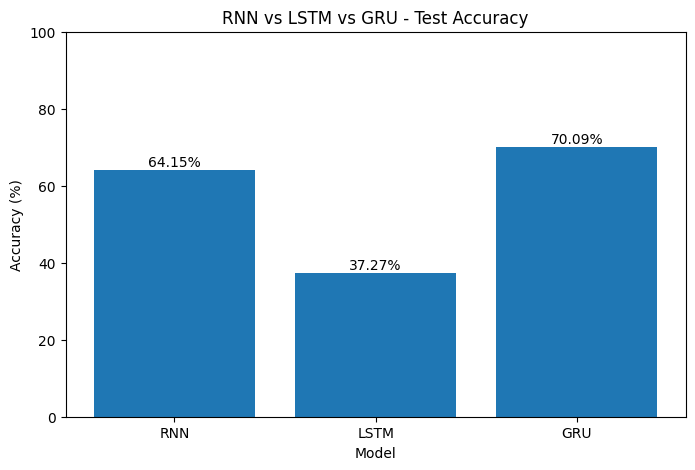

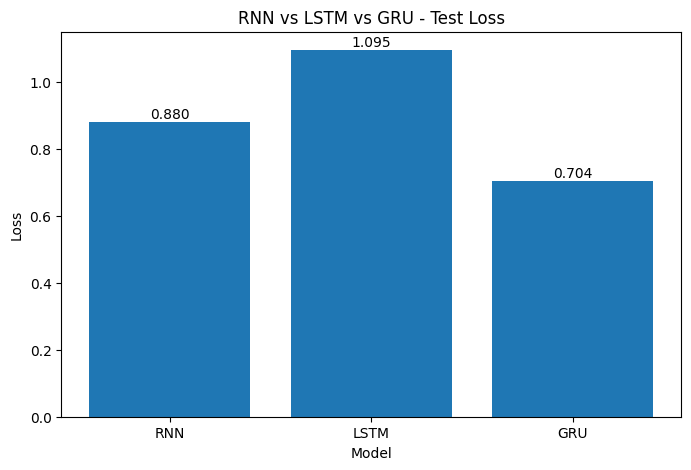

In [44]:
import matplotlib.pyplot as plt

# Test accuracy
accuracy_values = [
    test_accuracy_rnn_layers * 100,
    test_accuracy_lstm_layers * 100,
    test_accuracy_gru_layers * 100
]

# Test loss
loss_values = [
    test_loss_rnn_layers,
    test_loss_lstm_layers,
    test_loss_gru_layers
]

models = ["RNN", "LSTM", "GRU"]


# -----------------------------
# Accuracy comparison
# -----------------------------

plt.figure(figsize=(8, 5))

plt.bar(models, accuracy_values)

plt.title("RNN vs LSTM vs GRU - Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

for i, value in enumerate(accuracy_values):
    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()


# -----------------------------
# Loss comparison
# -----------------------------

plt.figure(figsize=(8, 5))

plt.bar(models, loss_values)

plt.title("RNN vs LSTM vs GRU - Test Loss")
plt.xlabel("Model")
plt.ylabel("Loss")

for i, value in enumerate(loss_values):
    plt.text(
        i,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.show()